Łączenie z serwerem IQM Odra 5...
Połączono z backendem: ODRA5 IQM Spark
Obwód transpilowany pomyślnie.
[START] Brak wcześniejszych plików wynikowych. Rozpoczynanie nowego zbierania od paczki 1.

PACZKA 1 / 130 (strzały: 1 – 10000 z 1300000)
Wysyłanie zadania (10000 shots) do IQM Odra 5...


c:\Users\grzeg\miniconda3\envs\qml\Lib\site-packages\iqm\qiskit_iqm\iqm_provider.py:197: UserWarning: Unknown backend option(s): {'memory': True}
  warnings.warn(f"Unknown backend option(s): {unknown_options}")


Zadanie w kolejce serwera. Oczekiwanie na zakończenie przetwarzania...
[Paczka 1/130] Aktualny status na Odra 5: QUEUED
[Paczka 1/130] Aktualny status na Odra 5: DONE
Zadanie zostało pomyślnie zakończone przez serwer!
[PODSUMOWANIE PACZKI 1/130]
  - Poprawne w paczce (A-P) : 8774 / 10000 (QBER paczki: 12.26%)
  - Łącznie zapisanych bitów: 8774 (skumulowany QBER: 12.26%)
  - Dopisano do 'sq1_public.txt', 'sq2_secret.txt', 'sq3_secret.txt', 'sq4_secret.txt' oraz 'sq5_control.txt'.

PACZKA 2 / 130 (strzały: 10001 – 20000 z 1300000)
Wysyłanie zadania (10000 shots) do IQM Odra 5...
Zadanie w kolejce serwera. Oczekiwanie na zakończenie przetwarzania...
[Paczka 2/130] Aktualny status na Odra 5: QUEUED
[Paczka 2/130] Aktualny status na Odra 5: DONE
Zadanie zostało pomyślnie zakończone przez serwer!
[PODSUMOWANIE PACZKI 2/130]
  - Poprawne w paczce (A-P) : 8894 / 10000 (QBER paczki: 11.06%)
  - Łącznie zapisanych bitów: 17668 (skumulowany QBER: 11.66%)
  - Dopisano do 'sq1_public.txt', 'sq2_sec

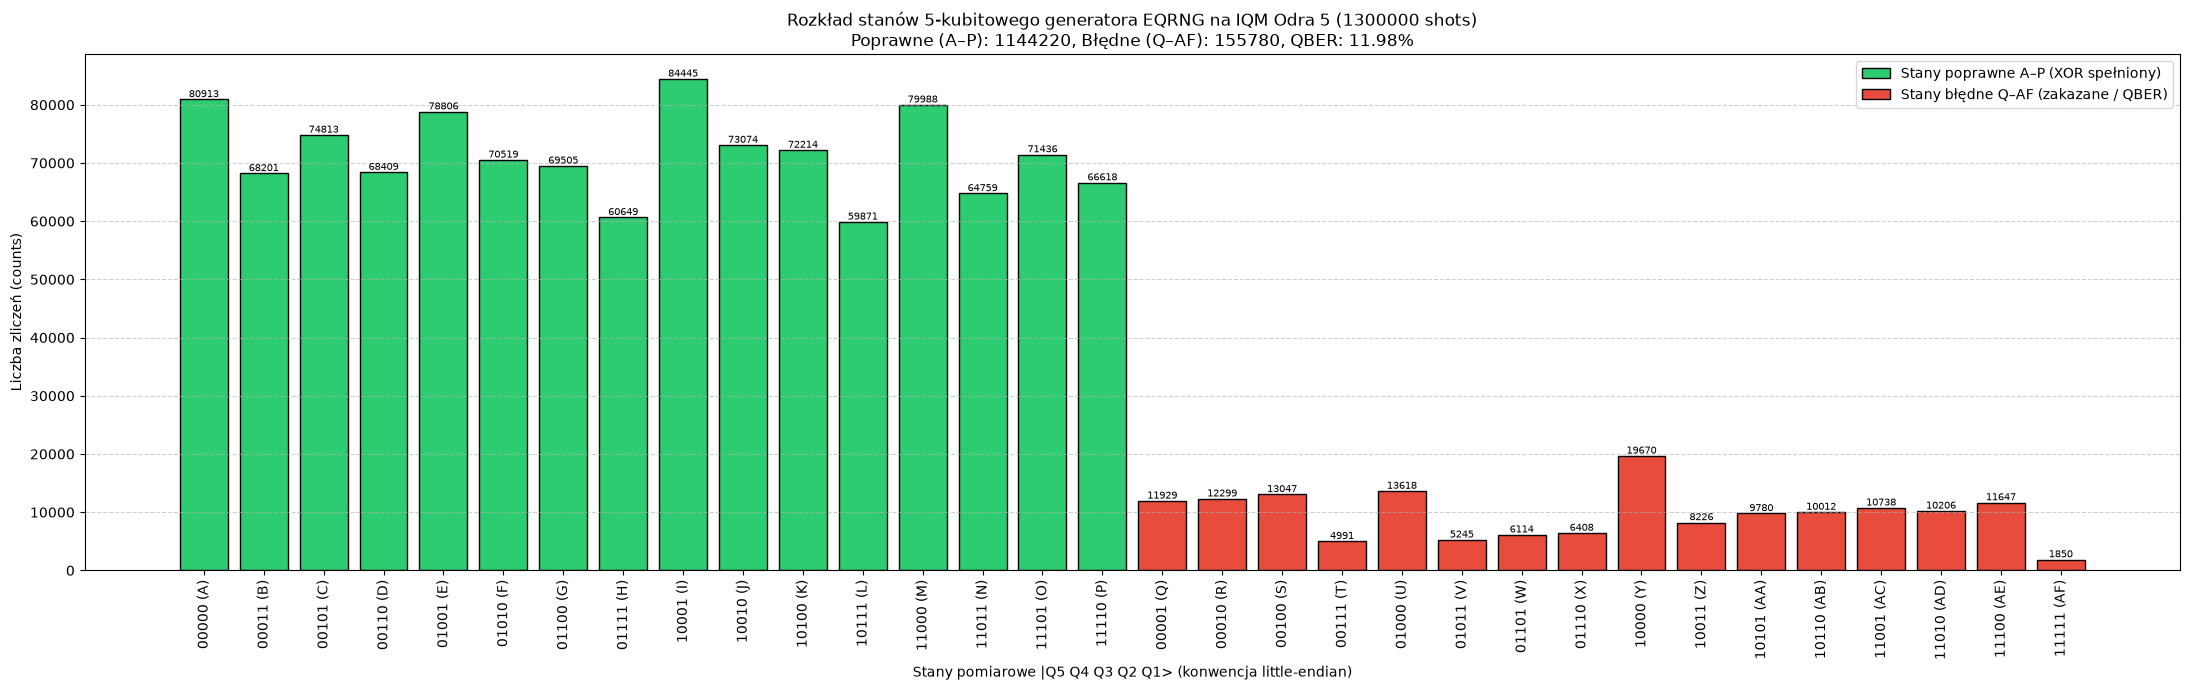

In [1]:
import os
import json
import time
import dotenv
from iqm.qiskit_iqm import IQMProvider
from qiskit import QuantumCircuit, transpile
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Konfiguracja globalna zbierania danych (2 000 000 shots w paczkach po 10 000)

ENV_FILE = "token.env"
PUBLIC_FILE = "sq1_public.txt"
SECRET_FILE = "sq2_secret.txt"
THIRD_FILE = "sq3_secret.txt"
FOURTH_FILE = "sq4_secret.txt"
CONTROL_FILE = "sq5_control.txt"
CHECKPOINT_FILE = "eqrng_checkpoint.json"
HISTOGRAM_FILE = "eqrng_histogram.png"

TOTAL_SHOTS = 1_300_000
BATCH_SHOTS = 10_000
TOTAL_BATCHES = TOTAL_SHOTS // BATCH_SHOTS

POLL_INTERVAL_SEC = 15      # Czas oczekiwania między sprawdzeniami statusu w kolejce
RETRY_DELAY_SEC = 15        # Czas oczekiwania po utracie połączenia przed ponowną próbą
MAX_STATUS_RETRIES = 50      # Liczba prób odpytania tego samego zadania przy chwilowym zaniku sieci

# Stany poprawne: parzysta liczba jedynek (Q5 = Q1 ^ Q2 ^ Q3 ^ Q4), zapis |Q5 Q4 Q3 Q2 Q1>
VALID_STATES = [format(i, "05b") for i in range(32) if bin(i).count("1") % 2 == 0]
ERROR_STATES = [format(i, "05b") for i in range(32) if bin(i).count("1") % 2 == 1]


def _state_label(index: int) -> str:
    """Zamienia numer stanu na etykietę literową: 0 -> A, 25 -> Z, 26 -> AA, ..."""
    index += 1
    name = ""
    while index > 0:
        index, rem = divmod(index - 1, 26)
        name = chr(65 + rem) + name
    return name


# 1. Połączenie z procesorem IQM Odra 5 (poprawiona autoryzacja bez konfliktów)

def get_backend(env_path: str = ENV_FILE):
    """Wczytuje dane autoryzacyjne z pliku token.env i zwraca obiekt backendu IQM Odra 5."""
    dotenv.load_dotenv(env_path, override=True)

    server_url = (
        os.getenv("IQM_SERVER_URL")
        or os.getenv("SERVER")
        or "https://odra5.e-science.pl/cocos"
    )
    token = os.getenv("IQM_TOKEN")

    if not token:
        raise ValueError(f"Nie znaleziono zmiennej IQM_TOKEN w pliku {env_path}!")

    os.environ["IQM_TOKEN"] = token
    provider = IQMProvider(server_url)
    return provider.get_backend()


# 2. Budowa i transpilacja obwodu 5-kubitowego EQRNG (z odpornością sieciową)

def build_eqrng_circuit() -> QuantumCircuit:
    """Buduje 5-kubitowy obwód EQRNG wytwarzający stan równej superpozycji 16 stanów o parzystej liczbie jedynek (Q5 = Q1 ^ Q2 ^ Q3 ^ Q4)."""
    eqrng = QuantumCircuit(5)
    eqrng.h(0)
    eqrng.h(1)
    eqrng.h(2)
    eqrng.h(3)
    eqrng.cx(0, 4)
    eqrng.cx(1, 4)
    eqrng.cx(2, 4)
    eqrng.cx(3, 4)
    eqrng.measure_all()
    return eqrng


def connect_and_prepare_circuit(eqrng: QuantumCircuit, env_path: str = ENV_FILE):
    """
    Nawiązuje połączenie z IQM Odra 5 i transpiluje obwód.
    W przypadku braku internetu ponawia próbę aż do skutku.
    """
    while True:
        try:
            print("Łączenie z serwerem IQM Odra 5...")
            backend = get_backend(env_path)
            print(f"Połączono z backendem: {backend.name}")

            # Transpilacja z optimization_level=3 przypisująca kubit docelowy (Q5, cel czterech bramek CX)
            # do centralnego kubitu Odry 5 bez bramek SWAP
            eqrng_transp = transpile(eqrng, backend=backend, optimization_level=3)
            print("Obwód transpilowany pomyślnie.")
            return backend, eqrng_transp
        except Exception as exc:
            print(
                f"[BŁĄD SIECI / POŁĄCZENIA] Nie udało się połączyć z Odra 5: {exc}\n"
                f"Ponowna próba za {RETRY_DELAY_SEC} sekund..."
            )
            time.sleep(RETRY_DELAY_SEC)


# 3. Wznowienie od miejsca przerwania (Checkpointing / State Recovery)

def _read_bits_file(filepath: str) -> str:
    """Wczytuje ciąg znaków '0'/'1' z pliku, jeśli plik istnieje."""
    if not os.path.exists(filepath):
        return ""
    with open(filepath, "r", encoding="utf-8") as f:
        return "".join(ch for ch in f.read() if ch in ("0", "1"))


def load_or_recover_state():
    """
    Sprawdza istnienie plików wynikowych (sq1_public.txt, sq2_secret.txt, sq3_secret.txt,
    sq4_secret.txt, sq5_control.txt) oraz pliku checkpointu. Zlicza zapisane bity, wyrównuje pliki
    w razie przerwania zapisu w połowie operacji i wyznacza dokładnie numer paczki,
    od której należy wznowić obliczenia.
    """
    all_states = VALID_STATES + ERROR_STATES
    counts = {state: 0 for state in all_states}
    completed_batches = 0
    valid_shots = 0
    error_shots = 0
    calibration_set_id = None

    sq5_existed = os.path.exists(CONTROL_FILE)

    content_sq1 = _read_bits_file(PUBLIC_FILE)
    content_sq2 = _read_bits_file(SECRET_FILE)
    content_sq3 = _read_bits_file(THIRD_FILE)
    content_sq4 = _read_bits_file(FOURTH_FILE)
    content_sq5 = _read_bits_file(CONTROL_FILE)

    saved_bits_sq1 = len(content_sq1)
    saved_bits_sq2 = len(content_sq2)
    saved_bits_sq3 = len(content_sq3)
    saved_bits_sq4 = len(content_sq4)
    saved_bits_sq5 = len(content_sq5)

    # Jeśli wcześniej zbierano tylko sq1, sq2, sq3 i sq4, a plik sq5 jeszcze nie istniał,
    # odtwarzamy brakujący ciąg sq5 z warunku parzystości XOR (sq5 = sq1 ^ sq2 ^ sq3 ^ sq4),
    # aby nie utracić dotychczas zebranych paczek.
    if (
        not sq5_existed
        and saved_bits_sq1 > 0 and saved_bits_sq2 > 0
        and saved_bits_sq3 > 0 and saved_bits_sq4 > 0
    ):
        common_len = min(saved_bits_sq1, saved_bits_sq2, saved_bits_sq3, saved_bits_sq4)
        print(
            f"[RECOVERY] Plik '{CONTROL_FILE}' nie istniał – odtwarzanie {common_len} bitów "
            f"ciągu S_Q5 z istniejących plików '{PUBLIC_FILE}', '{SECRET_FILE}', '{THIRD_FILE}' "
            f"i '{FOURTH_FILE}' (S_Q1 XOR S_Q2 XOR S_Q3 XOR S_Q4)..."
        )
        content_sq5 = "".join(
            str(int(content_sq1[i]) ^ int(content_sq2[i]) ^ int(content_sq3[i]) ^ int(content_sq4[i]))
            for i in range(common_len)
        )
        with open(CONTROL_FILE, "w", encoding="utf-8") as f5:
            f5.write(content_sq5)
        saved_bits_sq5 = len(content_sq5)

    # Jeśli któryś z 5 plików ma nadmiarowe bity po nagłym wyłączeniu zasilania,
    # wyrównujemy wszystkie pięć plików do wspólnej długości, aby zachować synchronizację
    saved_bits = min(saved_bits_sq1, saved_bits_sq2, saved_bits_sq3, saved_bits_sq4, saved_bits_sq5)
    if not (saved_bits_sq1 == saved_bits_sq2 == saved_bits_sq3 == saved_bits_sq4 == saved_bits_sq5):
        print(
            f"[RECOVERY] Wykryto różnicę długości plików "
            f"(SQ1: {saved_bits_sq1}, SQ2: {saved_bits_sq2}, SQ3: {saved_bits_sq3}, "
            f"SQ4: {saved_bits_sq4}, SQ5: {saved_bits_sq5} bitów). "
            f"Synchronizacja wszystkich 5 plików do {saved_bits} bitów..."
        )
        with open(PUBLIC_FILE, "w", encoding="utf-8") as f1:
            f1.write(content_sq1[:saved_bits])
        with open(SECRET_FILE, "w", encoding="utf-8") as f2:
            f2.write(content_sq2[:saved_bits])
        with open(THIRD_FILE, "w", encoding="utf-8") as f3:
            f3.write(content_sq3[:saved_bits])
        with open(FOURTH_FILE, "w", encoding="utf-8") as f4:
            f4.write(content_sq4[:saved_bits])
        with open(CONTROL_FILE, "w", encoding="utf-8") as f5:
            f5.write(content_sq5[:saved_bits])

    # Wczytanie dokładnych metadanych z pliku checkpointu (jeśli istnieje i jest spójny z plikami bitów)
    checkpoint_loaded = False
    if os.path.exists(CHECKPOINT_FILE):
        try:
            with open(CHECKPOINT_FILE, "r", encoding="utf-8") as fc:
                ckpt = json.load(fc)
            if ckpt.get("valid_shots") == saved_bits:
                completed_batches = int(ckpt.get("completed_batches", 0))
                valid_shots = int(ckpt.get("valid_shots", saved_bits))
                error_shots = int(ckpt.get("error_shots", 0))
                calibration_set_id = ckpt.get("calibration_set_id")
                for st, val in ckpt.get("counts", {}).items():
                    counts[st] = int(val)
                checkpoint_loaded = True
        except Exception as exc:
            print(f"[RECOVERY] Nie udało się odczytać pliku checkpointu ({exc}). Odtwarzanie z plików bitowych...")

    # Jeśli nie ma pliku checkpointu, ale istnieją pliki bitowe
    if not checkpoint_loaded and saved_bits > 0:
        valid_shots = saved_bits
        # Wyznaczenie liczby wykonanych paczek na podstawie zapisanych bitów
        completed_batches = min(TOTAL_BATCHES, (saved_bits + BATCH_SHOTS - 1) // BATCH_SHOTS)

    if saved_bits > 0 or completed_batches > 0:
        print(
            f"[WZNOWIENIE PRACY] Znaleziono istniejące dane na dysku:\n"
            f"  - Zapisane poprawne bity w 5 plikach: {saved_bits}\n"
            f"  - Ukończone paczki                  : {completed_batches} / {TOTAL_BATCHES}\n"
            f"  - Wznawianie od paczki nr           : {completed_batches + 1}"
        )
    else:
        print("[START] Brak wcześniejszych plików wynikowych. Rozpoczynanie nowego zbierania od paczki 1.")

    return completed_batches, counts, valid_shots, error_shots, calibration_set_id


def save_checkpoint(
    completed_batches: int,
    counts: dict,
    valid_shots: int,
    error_shots: int,
    calibration_set_id,
):
    """Zapisuje stan po każdej paczce, gwarantując spójne wznowienie pracy."""
    ckpt_data = {
        "completed_batches": completed_batches,
        "total_batches": TOTAL_BATCHES,
        "batch_shots": BATCH_SHOTS,
        "shots_processed": completed_batches * BATCH_SHOTS,
        "valid_shots": valid_shots,
        "error_shots": error_shots,
        "calibration_set_id": str(calibration_set_id) if calibration_set_id is not None else None,
        "counts": counts,
    }
    tmp_file = CHECKPOINT_FILE + ".tmp"
    with open(tmp_file, "w", encoding="utf-8") as fc:
        json.dump(ckpt_data, fc, indent=2, ensure_ascii=False)
        fc.flush()
        os.fsync(fc.fileno())
    os.replace(tmp_file, CHECKPOINT_FILE)


# Główny przebieg programu

eqrng = build_eqrng_circuit()
backend, eqrng_transp = connect_and_prepare_circuit(eqrng, ENV_FILE)

completed_batches, counts, valid_shots, error_shots, calibration_set_id = load_or_recover_state()

# 4. Pętla zbierająca 2 000 000 shots w paczkach po 10 000 z odpornością sieciową

for batch_idx in range(completed_batches + 1, TOTAL_BATCHES + 1):
    print(f"\n" + "=" * 75)
    print(
        f"PACZKA {batch_idx} / {TOTAL_BATCHES} "
        f"(strzały: {(batch_idx - 1) * BATCH_SHOTS + 1} – {batch_idx * BATCH_SHOTS} z {TOTAL_SHOTS})"
    )
    print("=" * 75)

    # ZABETONOWANY BLOK
    while True:
        try:
            print(f"Wysyłanie zadania ({BATCH_SHOTS} shots) do IQM Odra 5...")
            job = backend.run([eqrng_transp], shots=BATCH_SHOTS, memory=True)

            print("Zadanie w kolejce serwera. Oczekiwanie na zakończenie przetwarzania...")
            status_failures = 0

            while True:
                try:
                    status = job.status()
                    status_failures = 0  # Reset licznika po udanym odpytaniu
                except Exception as status_exc:
                    status_failures += 1
                    print(
                        f"[OSTRZEŻENIE SIECIOWE] Błąd podczas sprawdzania statusu zadania "
                        f"({status_failures}/{MAX_STATUS_RETRIES}): {status_exc}"
                    )
                    if status_failures >= MAX_STATUS_RETRIES:
                        raise RuntimeError(
                            "Przekroczono limit błędów odpytywania statusu. Wymagana rekonnektacja."
                        ) from status_exc
                    time.sleep(RETRY_DELAY_SEC)
                    continue

                status_str = status.name if hasattr(status, "name") else str(status)
                print(f"[Paczka {batch_idx}/{TOTAL_BATCHES}] Aktualny status na Odra 5: {status_str}")

                if status_str in ["DONE", "COMPLETED"]:
                    print("Zadanie zostało pomyślnie zakończone przez serwer!")
                    break
                elif status_str in ["CANCELLED", "ERROR", "FAILED"]:
                    raise RuntimeError(
                        f"Zadanie na serwerze Odra 5 zakończyło się błędem! Status: {status_str}"
                    )

                time.sleep(POLL_INTERVAL_SEC)

            # Pobranie rezultatów po zakończeniu pracy w kolejce
            job_result = job.result()
            batch_counts = job_result.get_counts()
            batch_memory = job_result.get_memory()

            break

        except KeyboardInterrupt:
            print(
                "\n[PRZERWANIE PRZEZ UŻYTKOWNIKA] Zatrzymano działanie skryptu. "
                "Dotychczasowe paczki są bezpiecznie zapisane na dysku."
            )
            raise
        except Exception as net_exc:
            print(
                f"\n[BŁĄD POŁĄCZENIA / SERWERA w paczce {batch_idx}]: {net_exc}\n"
                f"Oczekiwanie {RETRY_DELAY_SEC} s, ponowne nawiązanie sesji z IQM Odra 5 i powtórzenie paczki..."
            )
            time.sleep(RETRY_DELAY_SEC)
            backend, eqrng_transp = connect_and_prepare_circuit(eqrng, ENV_FILE)

    # Aktualizacja zliczeń stanów (counts) i identyfikatora kalibracji

    for state, count in batch_counts.items():
        clean_state = state.replace(" ", "")
        counts[clean_state] = counts.get(clean_state, 0) + count

    batch_shots_clean = [shot.replace(" ", "") for shot in batch_memory]

    if calibration_set_id is None:
        if hasattr(job_result, "parameters") and hasattr(job_result.parameters, "calibration_set_id"):
            calibration_set_id = job_result.parameters.calibration_set_id
        elif hasattr(job_result, "results") and len(job_result.results) > 0:
            calibration_set_id = getattr(job_result.results[0].header, "calibration_set_id", None)

    # 5. Wyodrębnienie ciągów bitowych (S_Q1, S_Q2, S_Q3, S_Q4, S_Q5) dla bieżącej paczki

    # Konwencja little-endian w Qiskit: każdy pomiar w `memory` ma kolejność (Q5, Q4, Q3, Q2, Q1)
    S_Q1 = []
    S_Q2 = []
    S_Q3 = []
    S_Q4 = []
    S_Q5 = []

    for shot in batch_shots_clean:
        S_Q1.append(int(shot[4]))  # kubit Q1 -> indeks [4]
        S_Q2.append(int(shot[3]))  # kubit Q2 -> indeks [3]
        S_Q3.append(int(shot[2]))  # kubit Q3 -> indeks [2]
        S_Q4.append(int(shot[1]))  # kubit Q4 -> indeks [1]
        S_Q5.append(int(shot[0]))  # kubit Q5 (centralny, kontrolny) -> indeks [0]

    # 6. Weryfikacja reguły XOR i filtracja błędów sprzętowych (QBER) w paczce
    batch_valid = 0   # Stany poprawne A-P: parzysta liczba jedynek
    batch_error = 0   # Stany zakazane Q-AF: nieparzysta liczba jedynek

    S_Q1_clean = []
    S_Q2_clean = []
    S_Q3_clean = []
    S_Q4_clean = []
    S_Q5_clean = []

    for i in range(len(batch_shots_clean)):
        if (S_Q1[i] ^ S_Q2[i] ^ S_Q3[i] ^ S_Q4[i]) == S_Q5[i]:
            batch_valid += 1
            S_Q1_clean.append(S_Q1[i])
            S_Q2_clean.append(S_Q2[i])
            S_Q3_clean.append(S_Q3[i])
            S_Q4_clean.append(S_Q4[i])
            S_Q5_clean.append(S_Q5[i])
        else:
            batch_error += 1

    valid_shots += batch_valid
    error_shots += batch_error
    total_measured_so_far = valid_shots + error_shots
    batch_qber = (batch_error / len(batch_shots_clean)) * 100.0 if batch_shots_clean else 0.0
    cumulative_qber = (error_shots / total_measured_so_far) * 100.0 if total_measured_so_far > 0 else 0.0

    # 7. Natychmiastowe dopisanie wszystkich 5 ciągów (S_Q1, S_Q2, S_Q3, S_Q4, S_Q5) do plików

    # Bieżące dopisywanie (Append mode) z wymuszeniem zapisu fizycznego na dysk (fsync)
    with open(PUBLIC_FILE, "a", encoding="utf-8") as f_pub:
        f_pub.write("".join(map(str, S_Q1_clean)))
        f_pub.flush()
        os.fsync(f_pub.fileno())

    with open(SECRET_FILE, "a", encoding="utf-8") as f_sec:
        f_sec.write("".join(map(str, S_Q2_clean)))
        f_sec.flush()
        os.fsync(f_sec.fileno())

    with open(THIRD_FILE, "a", encoding="utf-8") as f_third:
        f_third.write("".join(map(str, S_Q3_clean)))
        f_third.flush()
        os.fsync(f_third.fileno())

    with open(FOURTH_FILE, "a", encoding="utf-8") as f_fourth:
        f_fourth.write("".join(map(str, S_Q4_clean)))
        f_fourth.flush()
        os.fsync(f_fourth.fileno())

    with open(CONTROL_FILE, "a", encoding="utf-8") as f_ctrl:
        f_ctrl.write("".join(map(str, S_Q5_clean)))
        f_ctrl.flush()
        os.fsync(f_ctrl.fileno())

    # Zapis punktu kontrolnego (checkpointu) po udanym dopisaniu bitów
    save_checkpoint(
        completed_batches=batch_idx,
        counts=counts,
        valid_shots=valid_shots,
        error_shots=error_shots,
        calibration_set_id=calibration_set_id,
    )

    print(
        f"[PODSUMOWANIE PACZKI {batch_idx}/{TOTAL_BATCHES}]\n"
        f"  - Poprawne w paczce (A-P) : {batch_valid} / {len(batch_shots_clean)} (QBER paczki: {batch_qber:.2f}%)\n"
        f"  - Łącznie zapisanych bitów: {valid_shots} (skumulowany QBER: {cumulative_qber:.2f}%)\n"
        f"  - Dopisano do '{PUBLIC_FILE}', '{SECRET_FILE}', '{THIRD_FILE}', '{FOURTH_FILE}' oraz '{CONTROL_FILE}'."
    )


# 8. Podsumowanie końcowe i wizualizacja po zebraniu wszystkich paczek

total_measured = valid_shots + error_shots
qber_xor = (error_shots / total_measured) * 100.0 if total_measured > 0 else 0.0

print("\n" + "#" * 75)
print("ZAKOŃCZONO ZBIERANIE WSZYSTKICH PACZEK!")
print(f"Identyfikator kalibracji (calibration_set_id): {calibration_set_id}")
print(f"Zliczenia stanów (counts)   : {counts}")
print(f"Liczba wszystkich pomiarów  : {total_measured}")
print(f"Pomiary poprawne (stany A-P): {valid_shots}")
print(f"Pomiary błędne   (stany Q-AF): {error_shots}")
print(f"Poziom błędów XOR (QBER)    : {qber_xor:.2f}%")
print(
    f"Łącznie zapisano po {valid_shots} bitów w plikach "
    f"'{PUBLIC_FILE}', '{SECRET_FILE}', '{THIRD_FILE}', '{FOURTH_FILE}' oraz '{CONTROL_FILE}'."
)
print("#" * 75)

# Wykres słupkowy dla wszystkich 32 stanów (16 poprawnych A-P i 16 błędnych Q-AF)
valid_states = VALID_STATES
error_states = ERROR_STATES
states_order = valid_states + error_states
labels = [f"{state} ({_state_label(i)})" for i, state in enumerate(states_order)]

values = [counts.get(state, 0) for state in states_order]
colors = ["#2ecc71" if state in valid_states else "#e74c3c" for state in states_order]

plt.figure(figsize=(22, 7))
bars = plt.bar(labels, values, color=colors, edgecolor="black")
plt.xticks(rotation=90)

legend_patches = [
    Patch(facecolor="#2ecc71", edgecolor="black", label="Stany poprawne A–P (XOR spełniony)"),
    Patch(facecolor="#e74c3c", edgecolor="black", label="Stany błędne Q–AF (zakazane / QBER)"),
]
plt.legend(handles=legend_patches, loc="upper right")

plt.xlabel("Stany pomiarowe |Q5 Q4 Q3 Q2 Q1> (konwencja little-endian)")
plt.ylabel("Liczba zliczeń (counts)")
plt.title(
    f"Rozkład stanów 5-kubitowego generatora EQRNG na IQM Odra 5 ({total_measured} shots)\n"
    f"Poprawne (A–P): {valid_shots}, Błędne (Q–AF): {error_shots}, QBER: {qber_xor:.2f}%"
)
plt.grid(axis="y", linestyle="--", alpha=0.6)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height,
        f"{height}",
        ha="center",
        va="bottom",
        fontsize=7,
    )

plt.tight_layout()
plt.savefig(HISTOGRAM_FILE, dpi=150)
plt.show()